# Visualisations — storytelling features vs AI/human

Recreates the diagnostic figure:
1. ROC curve (logistic regression, 5-fold OOF)
2. Confusion matrix
3. Strongest model coefficients
4. Part-of-speech mix (if spaCy is available; otherwise skipped)

**Data:** `data/features_and_embeddings.csv` (falls back to `features_filtered_by_ai.csv`).

In [6]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

DATA = Path("../data")
FEATS = DATA / "features_and_embeddings.csv"
if not FEATS.exists():
    FEATS = DATA / "features_filtered_by_ai.csv"

In [8]:
df = pd.read_csv(FEATS)
print("Loaded", FEATS.name, "->", df.shape)

# Target
if "y" not in df.columns and "label" in df.columns:
    df["y"] = (df["label"].astype(str).str.lower() == "ai").astype(int)
y = df["y"].astype(int)

# Prefer a compact set of dialogue / storytelling features (matches the screenshot spirit)
DIALOGUE_CANDIDATES = [
    "lex_var_30", "mattr_30", "negation_rate", "first_person_rate", "second_person_rate",
    "reaction_rate", "contraction_rate", "question_rate", "exclaim_rate",
    "filler_rate", "profanity_rate", "short_sent_rate", "avg_sent_len",
    "discourse_markers_per100", "casual_verbs_per100", "slang_per100",
    "imperative_share", "blame_per100", "soap_emotion_per100", "cliche_per100",
    "gpt2_surprisal", "gltr_top10", "gpt2_entropy",
]
feature_cols = [c for c in DIALOGUE_CANDIDATES if c in df.columns]
if len(feature_cols) < 8:
    # Fall back to all numeric columns except y
    feature_cols = [c for c in df.select_dtypes("number").columns if c != "y"]

X = df[feature_cols].fillna(0)
print(f"{len(y)} transcripts | {y.sum()} AI / {(y == 0).sum()} human | {len(feature_cols)} features")
print("Features:", feature_cols)

Loaded features_and_embeddings.csv -> (364, 121)
364 transcripts | 172 AI / 192 human | 23 features
Features: ['lex_var_30', 'mattr_30', 'negation_rate', 'first_person_rate', 'second_person_rate', 'reaction_rate', 'contraction_rate', 'question_rate', 'exclaim_rate', 'filler_rate', 'profanity_rate', 'short_sent_rate', 'avg_sent_len', 'discourse_markers_per100', 'casual_verbs_per100', 'slang_per100', 'imperative_share', 'blame_per100', 'soap_emotion_per100', 'cliche_per100', 'gpt2_surprisal', 'gltr_top10', 'gpt2_entropy']


In [9]:
# 5-fold out-of-fold logistic regression
cv = StratifiedKFold(5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.3))
oof = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
pred = (oof >= 0.5).astype(int)

auc = roc_auc_score(y, oof)
bal_acc = balanced_accuracy_score(y, pred)
acc = accuracy_score(y, pred)
cm = confusion_matrix(y, pred)  # [[TN, FP], [FN, TP]] with human=0, AI=1

print(f"ROC-AUC: {auc:.3f}   Balanced accuracy: {bal_acc:.1%}   Accuracy: {acc:.1%}")
print("Confusion matrix (rows=true, cols=pred) [human, AI]:\n", cm)

ROC-AUC: 0.805   Balanced accuracy: 72.2%   Accuracy: 72.3%
Confusion matrix (rows=true, cols=pred) [human, AI]:
 [[142  50]
 [ 51 121]]


In [11]:
# Fit on all data for coefficient plot
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.3))
final.fit(X, y)
coefs = pd.Series(final.named_steps["logisticregression"].coef_[0], index=feature_cols)
coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

# Friendly display names for the coefficient chart
NAME_MAP = {
    "lex_var_30": "Lexical variety (30 words)",
    "mattr_30": "MATTR (30 words)",
    "negation_rate": "Negations",
    "first_person_rate": "First-person pronouns",
    "second_person_rate": "Second-person pronouns",
    "reaction_rate": "Conversational reactions",
    "contraction_rate": "Contractions",
    "question_rate": "Questions",
    "exclaim_rate": "Exclamations",
    "filler_rate": "Fillers",
    "profanity_rate": "Profanity",
    "short_sent_rate": "Short sentences",
    "avg_sent_len": "Avg sentence length",
    "discourse_markers_per100": "Discourse markers",
    "casual_verbs_per100": "Casual verbs",
    "slang_per100": "Slang",
    "imperative_share": "Imperatives",
    "blame_per100": "Blame language",
    "soap_emotion_per100": "Emotion language",
    "cliche_per100": "Conflict / cliché language",
    "gpt2_surprisal": "GPT-2 surprisal",
    "gltr_top10": "GLTR top-10 share",
    "gpt2_entropy": "GPT-2 entropy",
}
display_names = [NAME_MAP.get(c, c) for c in coefs.index]

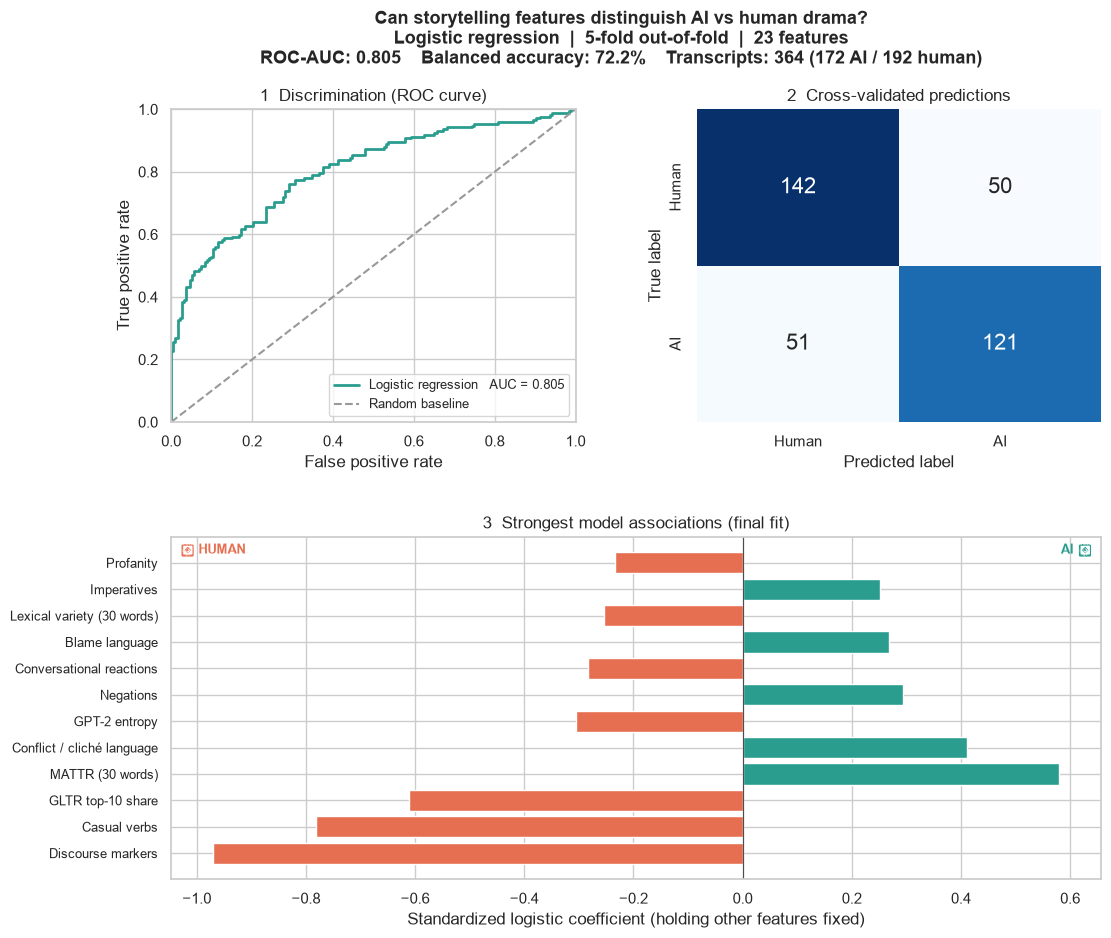

In [12]:
# ---- Main diagnostic figure (matches the screenshot layout) ----
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.05, 1.15], hspace=0.35, wspace=0.3)

# Header stats as figure title
fig.suptitle(
    "Can storytelling features distinguish AI vs human drama?\n"
    f"Logistic regression  |  5-fold out-of-fold  |  {len(feature_cols)} features\n"
    f"ROC-AUC: {auc:.3f}    Balanced accuracy: {bal_acc:.1%}    "
    f"Transcripts: {len(y)} ({int(y.sum())} AI / {int((y == 0).sum())} human)",
    fontsize=13, fontweight="bold", y=0.98,
)

# 1) ROC curve
ax1 = fig.add_subplot(gs[0, 0])
fpr, tpr, _ = roc_curve(y, oof)
ax1.plot(fpr, tpr, color="#2a9d8f", lw=2, label=f"Logistic regression   AUC = {auc:.3f}")
ax1.plot([0, 1], [0, 1], ls="--", color="0.6", label="Random baseline")
ax1.set_xlabel("False positive rate")
ax1.set_ylabel("True positive rate")
ax1.set_title("1  Discrimination (ROC curve)")
ax1.legend(loc="lower right", fontsize=9)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)

# 2) Confusion matrix (human top-left style of the screenshot)
ax2 = fig.add_subplot(gs[0, 1])
# Screenshot order: rows = true Human / AI, cols = predicted Human / AI
# cm is [[TN, FP], [FN, TP]] for human=0, AI=1
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax2,
    xticklabels=["Human", "AI"], yticklabels=["Human", "AI"],
    annot_kws={"size": 16},
)
ax2.set_xlabel("Predicted label")
ax2.set_ylabel("True label")
ax2.set_title("2  Cross-validated predictions")

# 3) Coefficients (top features by |coef|)
ax3 = fig.add_subplot(gs[1, :])
top = coefs.head(12)
colors = ["#e76f51" if v < 0 else "#2a9d8f" for v in top.values]
ax3.barh(range(len(top))[::-1], top.values[::-1], color=colors[::-1])
ax3.set_yticks(range(len(top))[::-1])
ax3.set_yticklabels([NAME_MAP.get(c, c) for c in top.index[::-1]], fontsize=9)
ax3.axvline(0, color="0.3", lw=0.8)
ax3.set_xlabel("Standardized logistic coefficient (holding other features fixed)")
ax3.set_title("3  Strongest model associations (final fit)")
ax3.text(0.01, 0.98, "◀ HUMAN", transform=ax3.transAxes, va="top", ha="left",
         color="#e76f51", fontsize=9, fontweight="bold")
ax3.text(0.99, 0.98, "AI ▶", transform=ax3.transAxes, va="top", ha="right",
         color="#2a9d8f", fontsize=9, fontweight="bold")

fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


In [13]:
# Part-of-speech mix (optional — needs spaCy + en_core_web_sm)
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
except Exception as e:
    print("spaCy model not available — skipping POS chart.")
    print("Install with:  python -m spacy download en_core_web_sm")
    nlp = None

if nlp is not None and "transcript" in df.columns:
    POS_ORDER = ["NOUN", "VERB", "ADJ", "ADV", "PRON", "ADP", "DET",
                 "CCONJ", "NUM", "PART", "INTJ"]
    POS_LABELS = ["Nouns", "Verbs", "Adjectives", "Adverbs", "Pronouns",
                  "Prepositions", "Determiners", "Conjunctions", "Numbers",
                  "Particles", "Other/interjections"]

    def pos_shares(text):
        doc = nlp(str(text))
        counts = {p: 0 for p in POS_ORDER}
        n = 0
        for tok in doc:
            if tok.is_space or tok.is_punct:
                continue
            n += 1
            if tok.pos_ in counts:
                counts[tok.pos_] += 1
            else:
                counts["INTJ"] += 1  # bucket rare tags with interjections
        if n == 0:
            return [0.0] * len(POS_ORDER)
        return [100 * counts[p] / n for p in POS_ORDER]

    rows = [pos_shares(t) for t in df["transcript"]]
    pos_df = pd.DataFrame(rows, columns=POS_LABELS)
    pos_df["label"] = y.map({0: "Human", 1: "AI"})

    means = pos_df.groupby("label")[POS_LABELS].mean().T
    means = means[["AI", "Human"]]  # AI first (orange), Human second (blue)

    ax = means.plot(kind="bar", figsize=(11, 4), color=["#e76f51", "#457b9d"], width=0.75)
    ax.set_ylabel("% of words")
    ax.set_title("Part-of-speech mix (average % of words per transcript)")
    ax.set_xticklabels(POS_LABELS, rotation=30, ha="right")
    ax.legend(title="label")
    plt.tight_layout()
    plt.show()


spaCy model not available — skipping POS chart.
Install with:  python -m spacy download en_core_web_sm


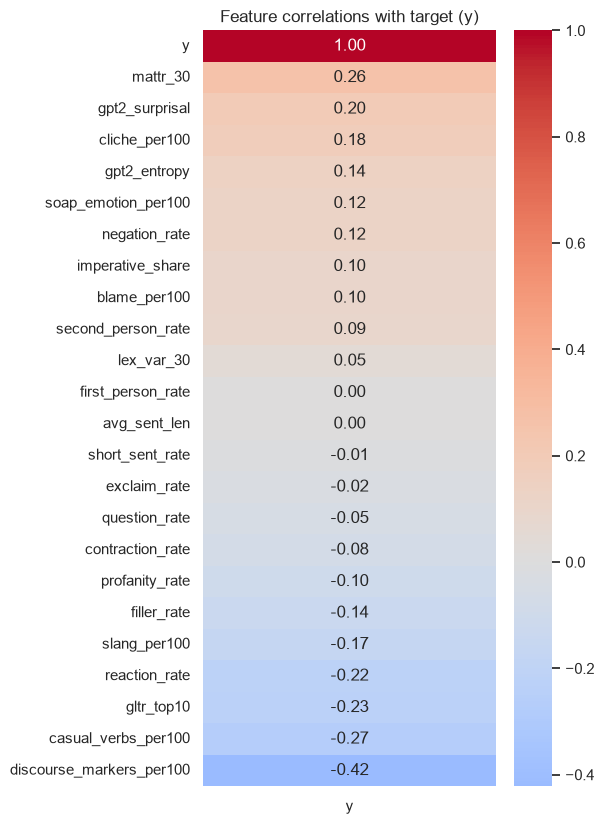

In [14]:
# Correlation heatmap with target (handy extra)
numeric = df[feature_cols + ["y"]].apply(pd.to_numeric, errors="coerce")
corr = numeric.corr()[["y"]].sort_values("y", ascending=False)

plt.figure(figsize=(6, max(4, 0.35 * len(corr))))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Feature correlations with target (y)")
plt.tight_layout()
plt.show()